#Part A – Gaussian Naive Bayes on a Numeric Dataset

In [203]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import classification_report, accuracy_score,confusion_matrix, precision_score, recall_score, f1_score
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB

sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (7, 4)

In [204]:
#dataset loead
data=load_breast_cancer()
X=data.data
y=data.target

data = load_breast_cancer()
X = data.data
y = data.target

print('Shape of X (features):', X.shape)
print('Shape of y (labels):', y.shape)
print('Target names:', data.target_names)
print('\nFirst 5 feature names:')
print(data.feature_names[:5])

Shape of X (features): (569, 30)
Shape of y (labels): (569,)
Target names: ['malignant' 'benign']

First 5 feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness']


In [205]:
#dataframe create
df=pd.DataFrame(X, columns=data.feature_names)
df['target']=y
df.head(4)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,radius error,texture error,perimeter error,area error,smoothness error,compactness error,concavity error,concave points error,symmetry error,fractal dimension error,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0


In [206]:
#class distribution
class_counts= df['target'].value_counts()
print(class_counts)

target
1    357
0    212
Name: count, dtype: int64


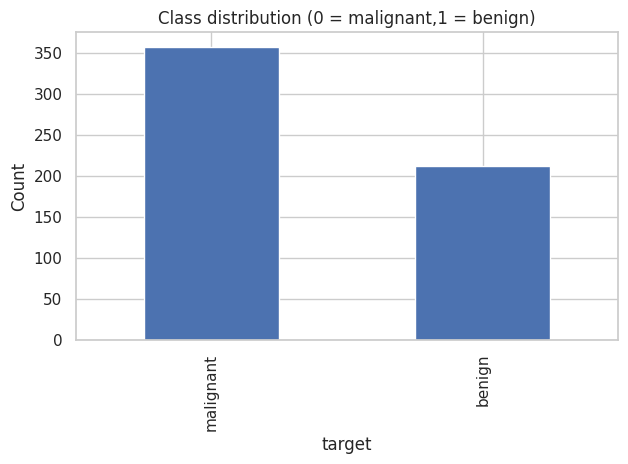

In [207]:
class_counts.plot(kind='bar')
plt.xticks(ticks=[0,1], labels=data.target_names)
plt.title('Class distribution (0 = malignant,1 = benign)')
plt.ylabel('Count')
plt.show()

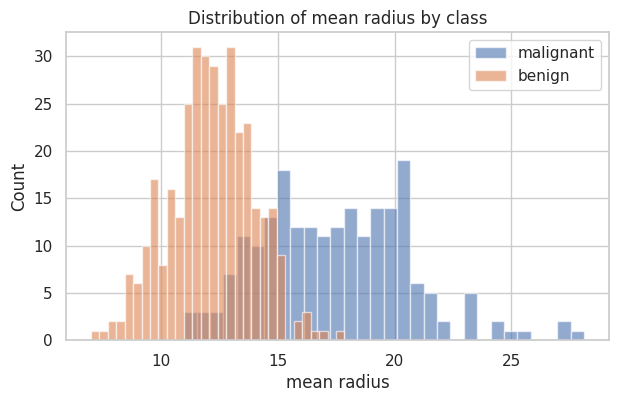

In [208]:
# Simple Feature Visualization
feature_name='mean radius'
feat_idx= list(data.feature_names).index(feature_name)

plt.figure()
plt.hist(X[y==0][:,feat_idx], bins=30, alpha=0.6, label='malignant')
plt.hist(X[y==1][:,feat_idx], bins=30, alpha=0.6, label='benign')
plt.legend()
plt.xlabel(feature_name)
plt.ylabel('Count')
plt.title(f'Distribution of {feature_name} by class')
plt.show()

In [209]:
#train test split
X_train, X_test, y_train, y_test= train_test_split( X,y, test_size=0.25, random_state=42,stratify=y)
print("Training set shape:", X_train.shape)
print("Test set shape:", X_test.shape)

Training set shape: (426, 30)
Test set shape: (143, 30)


In [210]:
from numpy.random import gumbel
#  Train Gaussian Naive
gnb= GaussianNB()
gnb.fit(X_train, y_train)

#predict
y_pred= gnb.predict(X_test)
print('accuracy:', accuracy_score(y_test, y_pred))

accuracy: 0.9370629370629371


confusion matrix:
 [[46  7]
 [ 2 88]]


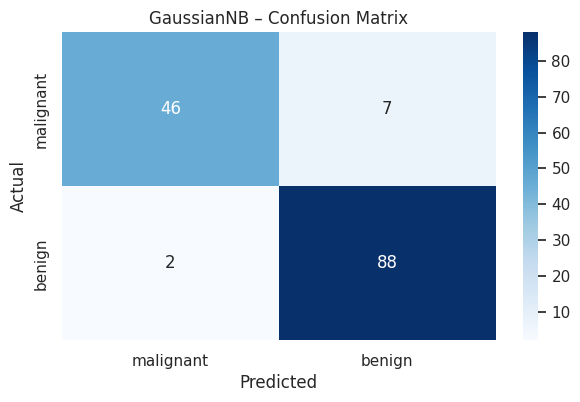

In [211]:
#confusion matrix
cm=confusion_matrix(y_test,y_pred)
print('confusion matrix:\n',cm)

sns.heatmap(cm, annot=True, fmt='d' ,cmap='Blues',
            xticklabels=data.target_names,
            yticklabels=data.target_names

            )
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('GaussianNB – Confusion Matrix')
plt.show()

In [212]:
#classification report
print("classification report:\n", classification_report(y_test, y_pred))

classification report:
               precision    recall  f1-score   support

           0       0.96      0.87      0.91        53
           1       0.93      0.98      0.95        90

    accuracy                           0.94       143
   macro avg       0.94      0.92      0.93       143
weighted avg       0.94      0.94      0.94       143



#Part B – Multinomial Naive Bayes on Text Data

In [213]:
texts=[
    'I love this product',
    'this is  amazing and fantastic',
    'I really likt this',
    'I hate this item',
    'This is the worst think ever',
    'Horrible and terrible experience',
]

label=[1, 1, 1, 0, 0, 0]

toy_df= pd.DataFrame({
    'text':texts,
    'label':label
})
toy_df

,text,label
0,I love this product,1
1,this is amazing and fantastic,1
2,I really likt this,1
3,I hate this item,0
4,This is the worst think ever,0
5,Horrible and terrible experience,0


In [214]:
# Convert Text to Features with CountVectorizer
vectorizer= CountVectorizer()
X_toy= vectorizer.fit_transform(toy_df['text'])
y_toy=toy_df['label']

print("Feature matrix shape: ", X_toy.shape)
print("Vocubulary: ", vectorizer.get_feature_names_out())

Feature matrix shape:  (6, 18)
Vocubulary:  ['amazing' 'and' 'ever' 'experience' 'fantastic' 'hate' 'horrible' 'is'
 'item' 'likt' 'love' 'product' 'really' 'terrible' 'the' 'think' 'this'
 'worst']


In [215]:
# Train MultinomialNB on Tiny Dataset
mnb_toy = MultinomialNB()
mnb_toy.fit(X_toy, y_toy)

y_toy_pred = mnb_toy.predict(X_toy)
print('Accuracy on tiny dataset: ', accuracy_score(y_toy,y_toy_pred))
print('Classification repot: ')
print(classification_report(y_toy,y_toy_pred))

Accuracy on tiny dataset:  1.0
Classification repot: 
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         3
           1       1.00      1.00      1.00         3

    accuracy                           1.00         6
   macro avg       1.00      1.00      1.00         6
weighted avg       1.00      1.00      1.00         6



In [216]:
# Try New Sentences
new_texts = [
    'I love it',
    'This product is horrible',
    'Fantastic experience',
    'Worst purchase ever'
]
X_new = vectorizer.transform(new_texts)
new_pred = mnb_toy.predict(X_new)

for txt, pred in zip(new_texts, new_pred):
    label_str = 'positive' if pred == 1 else 'negative'
    print(f'{txt!r} -> {label_str}')

'I love it' -> positive
'This product is horrible' -> positive
'Fantastic experience' -> positive
'Worst purchase ever' -> negative


# 3 - use real datasets
##Scaling Up: 20 Newsgroups Subset

In [217]:

from sklearn.datasets import fetch_20newsgroups
categories=['comp.graphics', 'rec.sport.baseball', 'sci.med']

newsgroups= fetch_20newsgroups(
    subset = 'train',
    categories= categories,
    remove= ('headers', 'footers', 'quotes'),
    shuffle= True,
    random_state=42
)

In [218]:
df_news = pd.DataFrame({
    'text': newsgroups.data,
    'label': newsgroups.target
})
df_news.head()

,text,label
0,"\nThe FDA, I believe. Rules say no blood or b...",2
1,,2
2,It would be nice to think that individuals can...,2
3,"Ok all you trivia buffs, I have a good one for...",1
4,"Please , I need the starting address (pointer)...",0


In [219]:
print('Number of document:', len(newsgroups.data))
print('Target name:', newsgroups.target_names)

Number of document: 1775
Target name: ['comp.graphics', 'rec.sport.baseball', 'sci.med']


In [220]:
#train
X_train_text, X_test_text, y_train_text, y_test_text = train_test_split(df_news['text'], df_news['label'], test_size=0.25, random_state=42)
print('Train size:', X_train_text.shape[0])
print('Test size:', X_test_text.shape[0])

Train size: 1331
Test size: 444


In [221]:
#Vectorize Text with CountVectorizer
vectorizer_news = CountVectorizer(stop_words='english', max_features=3000)
X_train_counts = vectorizer_news.fit_transform(X_train_text)
X_test_counts = vectorizer_news.transform(X_test_text)


print('Shape of X_train_counts:', X_train_counts.shape)
print('Shape of X_test_counts:', X_test_counts.shape)

Shape of X_train_counts: (1331, 3000)
Shape of X_test_counts: (444, 3000)


In [222]:
#train model
mnb_news = MultinomialNB()
mnb_news.fit(X_train_counts, y_train_text)

MultinomialNB()

Accuracy on 20 Newsgroups subset: 0.9166666666666666
Confusion matrix:
 [[131   5   7]
 [  6 132   9]
 [  4   6 144]]


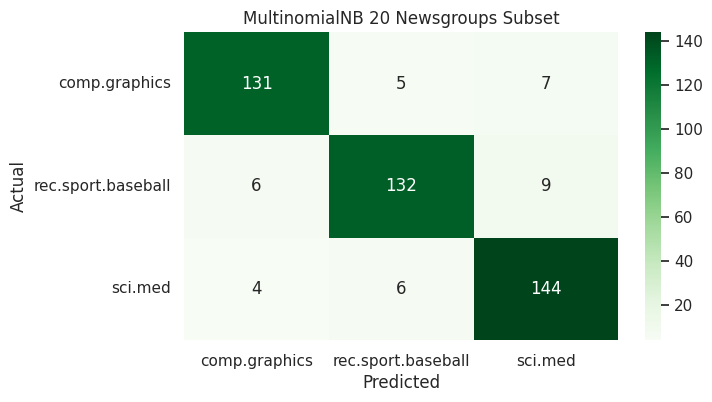

Classification report:
                    precision    recall  f1-score   support

     comp.graphics       0.93      0.92      0.92       143
rec.sport.baseball       0.92      0.90      0.91       147
           sci.med       0.90      0.94      0.92       154

          accuracy                           0.92       444
         macro avg       0.92      0.92      0.92       444
      weighted avg       0.92      0.92      0.92       444



In [223]:
#Evaluate MultinomialNB News Data
y_news_pred = mnb_news.predict(X_test_counts)
acc_news = accuracy_score(y_test_text, y_news_pred)
print('Accuracy on 20 Newsgroups subset:', acc_news)

cm_news = confusion_matrix(y_test_text, y_news_pred)
print('Confusion matrix:\n', cm_news)

sns.heatmap(cm_news, annot=True, fmt='d', cmap='Greens',
            xticklabels=newsgroups.target_names,
            yticklabels=newsgroups.target_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('MultinomialNB 20 Newsgroups Subset')
plt.show()


print('Classification report:')
print(classification_report(y_test_text, y_news_pred, target_names=newsgroups.target_names))